# Detection v4: a multi-channel Sethi detector against the v7 adversary

Detection v3 ran Sethi et al.'s detector on the v7 sweeps and found two weaknesses:

- **Active markets.** Honest wallets close their positions about as often as random walks do,
  so the closure score barely separates them from wash wallets.
- **Rotating pool.** When the adversary rotates through a large wallet pool, each wash wallet
  closes only about once.

v4 keeps Sethi's network step (Part II) and adds Part I evidence that looks at short time
windows:

- **closure**: Sethi's initial score, unchanged (= v3).
- **roundtrip_W** (W = 50, 100, 200): the share of a wallet's units that it undoes within W steps.
- **repeat_W** (W = 20, 50, 200): the share of a wallet's volume on ordered pairs
  (seller → buyer) that trade again within W steps.

Each channel is propagated over the counterparty graph. Each is then mapped to its tail
probability over honest volume in the background's control runs, and **v4** flags a pair on its
most extreme channel. Thresholds hold the pooled control FPR at 1%, with a score floor of 0.5
(see `fusion.py`). The data are the five `washtrade/v7` sweeps at 200 seeds (104,000 runs).

This notebook only reads results. Set `RUN_DETECTION = True` to rerun detection, which takes about
40 minutes with 15 jobs.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v7 import design as D
from washtrade.v7 import generate as G
from detection.v4 import experiment as X
from detection.v4.fusion import FLOORS, MAIN_FLOOR, floor_tag

DET4 = ROOT / "capstone codes" / "detection" / "v4"

## Configuration

In [2]:
# Folder holding ds_v7_<sweep>/. Set the WASH_V7_DATA environment variable, or edit this line.
DATA = Path(os.environ.get("WASH_V7_DATA") or (ROOT / "capstone codes" / "washtrade" / "v7" / "data"))
RUN_DETECTION = False                 # True = smoke test + detection on every sweep (~40 min)
JOBS = max(1, (os.cpu_count() or 2) - 1)
SWEEPS = list(D.SWEEPS)
missing = [sw for sw in SWEEPS if not (Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv").exists()]
print("sweeps:", SWEEPS, "| missing datasets:", missing or "none")

sweeps: ['scenarios', 'rotation', 'size', 'residual', 'evasive'] | missing datasets: none


## 1. Smoke test and detection (only if `RUN_DETECTION`)

In [3]:
if RUN_DETECTION:
    res = subprocess.run([sys.executable, str(DET4 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    print(res.stdout.splitlines()[-1])
    if res.returncode != 0:
        raise RuntimeError("smoke test failed:\n" + res.stdout[-2000:])
    t0 = time.time()
    X.run_all(SWEEPS, jobs=JOBS, data=str(DATA))
    print(f"detection done in {(time.time() - t0) / 60:.0f} min")
else:
    print("RUN_DETECTION is False: reading existing results")

RUN_DETECTION is False: reading existing results


## 2. Load results

In [4]:
MAN = ["run_id", "zero_returns_per_used_wallet", "events_per_pair_mean"]


def load(sw):
    r = pd.read_csv(Path(X.out_dir(sw, str(DATA))) / "results.csv")
    m = pd.read_csv(Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv", usecols=MAN)
    return r.merge(m, on="run_id", how="left")


R = {sw: load(sw) for sw in SWEEPS}
TH = pd.read_csv(DATA / "detection_v4_thresholds.csv")
print({sw: f"{R[sw]['run_id'].nunique()} runs x {R[sw]['method'].nunique()} methods" for sw in SWEEPS})

BG4 = ["thin", "thick", "active", "active_dense"]
BG3 = ["thin", "thick", "active"]
BG5 = ["thin", "thick", "active_thin", "active", "active_dense"]
COLOR = {"thin": "#2a78d6", "thick": "#eb6834", "active_thin": "#eda100", "active": "#1baf7a",
         "active_dense": "#e87ba4"}                # same as detection v2 / v3
MARKER = {"thin": "o", "thick": "s", "active_thin": "D", "active": "^", "active_dense": "v"}
MAIN = ["closure", "roundtrip_100", "repeat_50", "closure+roundtrip", "closure+repeat", "v4"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})


def pooled(df, by, tp="trade_tp", fp="trade_fp"):
    # Volume-pooled recall, precision and FPR (sum over runs, then divide), plus mean AP.
    g = df.groupby(by)
    s = g[[tp, fp, "trade_pos", "trade_neg"]].sum()
    out = pd.DataFrame({"recall": s[tp] / s["trade_pos"],
                        "precision": s[tp] / (s[tp] + s[fp]),
                        "fpr": s[fp] / s["trade_neg"]})
    out["ap"] = g["trade_ap"].mean()
    out["runs"] = g["run_id"].nunique()
    return out


def mean_ci(df, by, col):
    out = df.groupby(by)[col].agg(["mean", "std", "count"]).reset_index()
    out["half"] = 1.96 * out["std"].fillna(0) / np.sqrt(out["count"])
    return out


def heat(ax, piv, vmin=0, vmax=1, cmap="Blues", fmt="{:.2f}"):
    ax.imshow(piv.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(piv.shape[1]), piv.columns, rotation=0)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if (v - vmin) / (vmax - vmin) > 0.6 else "#0b0b0b")

{'scenarios': '12000 runs x 12 methods', 'rotation': '14400 runs x 12 methods', 'size': '8400 runs x 12 methods', 'residual': '10800 runs x 12 methods', 'evasive': '58400 runs x 12 methods'}


## 3. Thresholds

Pooled control FPR target 1%, score floor 0.5. For the closure channel the calibrated
threshold equals v3's, up to v3's 0.01 grid. For single channels the table shows the effective
threshold on the raw score, max(θ, floor): the floor is binding wherever honest control scores
never reach 0.5. For the fused methods θ is on the fused scale $z = 1 - \min_k u_k$, so θ = 0.997
means "less than 0.3% of honest control volume looks at least this suspicious on the most
extreme channel".

In [5]:
th = TH[TH["floor"] == MAIN_FLOOR].copy()
single = ~th["method"].isin(["closure+roundtrip", "closure+repeat", "v4"])
th["theta_eff"] = np.where(single, np.maximum(th["theta_1"], MAIN_FLOOR), th["theta_1"])
display(th.pivot(index="method", columns="background", values="theta_eff")[BG5].round(3))

background,thin,thick,active_thin,active,active_dense
method,,,,,
closure,0.840,0.809,0.989,0.980,0.963
closure+repeat,0.992,0.990,0.990,0.990,0.990
closure+roundtrip,0.995,0.997,0.995,0.997,0.997
repeat_20,0.500,0.609,0.500,0.500,0.500
repeat_200,0.623,0.615,0.500,0.500,0.500
repeat_50,0.500,0.609,0.500,0.500,0.500
repeat_50_noprop,0.500,0.500,0.500,0.500,0.500
roundtrip_100,0.517,0.570,0.500,0.642,0.643
roundtrip_100_noprop,0.667,0.727,0.545,0.720,0.727


## 4. Mechanism: what each channel sees

`scenarios` sweep, the per-wallet table. The bars show the mean propagated score $x$ of wash
wallets (solid) and honest wallets (light) in four scenarios. **triad** is a fixed triad.
**pool96** draws each round's 3 wallets from a pool of 96. **evasive** uses a pool of 12,
rounds of 1–4 units and residuals. **evasive_camo** is evasive plus camouflage.

- **Closure, active markets:** honest wallets score about as high as wash wallets, which is the
  failure v3 found.
- **Round-trip:** keeps a gap in every scenario. A wash round undoes its positions within
  roughly 100 steps; an honest trader only does so over its long gaps between arrivals.
- **Repeat:** is high wherever a round trades several units on one edge, and near zero for
  honest wallets. It is blind to size-1 rounds (pool96).

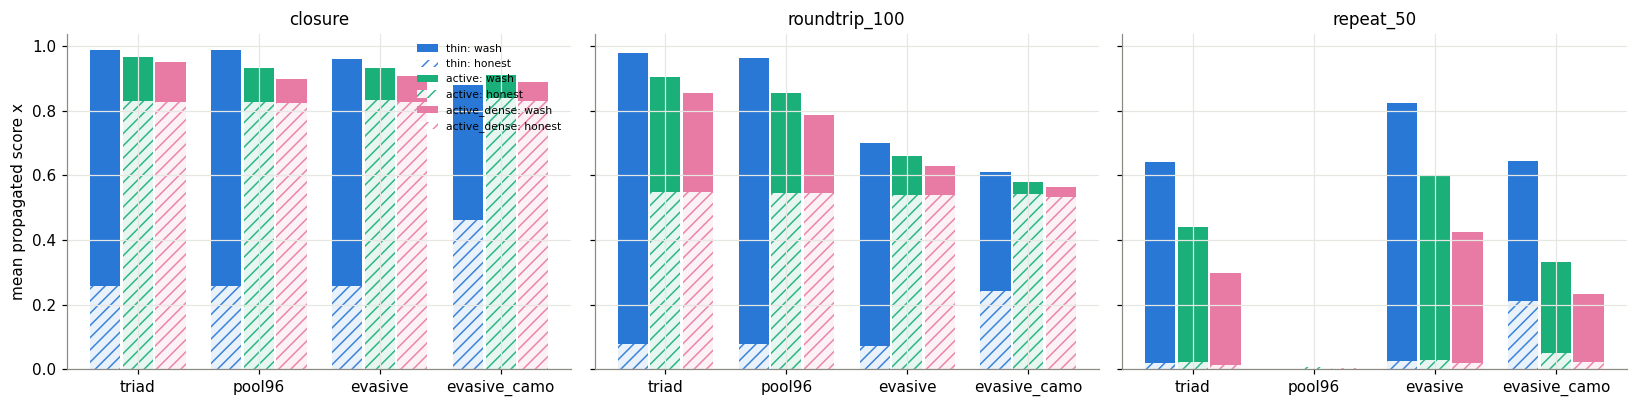

In [6]:
WAL = pd.read_csv(Path(X.out_dir("scenarios", str(DATA))) / "wallets.csv",
                  usecols=["run_id", "f_scenario", "background", "is_wash",
                           "x_closure", "x_roundtrip_100", "x_repeat_50"])
SC = {"triad": "triad", "triad_pool96": "pool96", "triad_evasive": "evasive", "evasive_camo": "evasive_camo"}
CH = [("x_closure", "closure"), ("x_roundtrip_100", "roundtrip_100"), ("x_repeat_50", "repeat_50")]
wa = WAL[WAL["f_scenario"].isin(SC)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
xs = np.arange(len(SC))
for ax, (col, title) in zip(axes, CH):
    for k, b in enumerate(["thin", "active", "active_dense"]):
        m = wa[wa.background == b].groupby(["f_scenario", "is_wash"])[col].mean().unstack()
        m = m.reindex(list(SC))
        off = (k - 1) * 0.27
        ax.bar(xs + off, m[True], 0.25, color=COLOR[b], label=f"{b}: wash")
        ax.bar(xs + off, m[False], 0.25, color="white", edgecolor=COLOR[b], hatch="///",
               linewidth=0, alpha=0.9, label=f"{b}: honest")
    ax.set_xticks(xs, list(SC.values()))
    ax.set_title(title)
axes[0].set_ylabel("mean propagated score x")
axes[0].legend(fontsize=7, ncol=1, loc="upper right")
fig.tight_layout()

## 5. Headline: v3 (closure) vs v4, fixed triad and all four tactics

`evasive` sweep. **Fixed triad**: pool 3, Q = 1, no residual, no camouflage. **All four**:
pool 96, Q in 1..4, residual on half of the rounds, camouflage. Values are pooled over the 200
seeds of each cell.

- Top row: recall at the calibrated threshold.
- Bottom row: FPR on the honest volume **of the wash runs**. Spillover makes it differ from the
  1% control target.

fpr                           recall        \
adv                all four       fixed triad       all four         
method              closure    v4     closure    v4  closure    v4   
background   f_gap                                                   
thin         0.0       0.05  0.07        0.01  0.02     0.65  0.98   
             5.0       0.05  0.08        0.04  0.06     0.58  0.96   
             20.0      0.03  0.04        0.09  0.12     0.38  0.71   
thick        0.0       0.04  0.04        0.03  0.03     0.69  0.95   
             5.0       0.05  0.04        0.06  0.08     0.57  0.83   
             20.0      0.03  0.01        0.08  0.09     0.36  0.39   
active       0.0       0.00  0.00        0.02  0.03     0.08  0.65   
             5.0       0.00  0.00        0.02  0.04     0.01  0.08   
             20.0      0.00  0.00        0.01  0.02     0.00  0.01   
active_dense 0.0       0.00  0.00        0.03  0.03     0.13  0.42   
             5.0       0.00  0.00        0.02  0.02     0.04  0.06   
             20.0      0.00  0.00        0.02  0.02     0.01  0.02   

                                      
adv                fixed triad        
method                 closure    v4  
background   f_gap                    
thin         0.0          0.97  1.00  
             5.0          0.90  1.00  
             20.0         0.80  1.00  
thick        0.0          0.97  1.00  
             5.0          0.86  1.00  
             20.0         0.82  1.00  
active       0.0          0.46  1.00  
             5.0          0.06  1.00  
             20.0         0.02  0.32  
active_dense 0.0          0.52  1.00  
             5.0          0.03  0.95  
             20.0         0.01  0.27

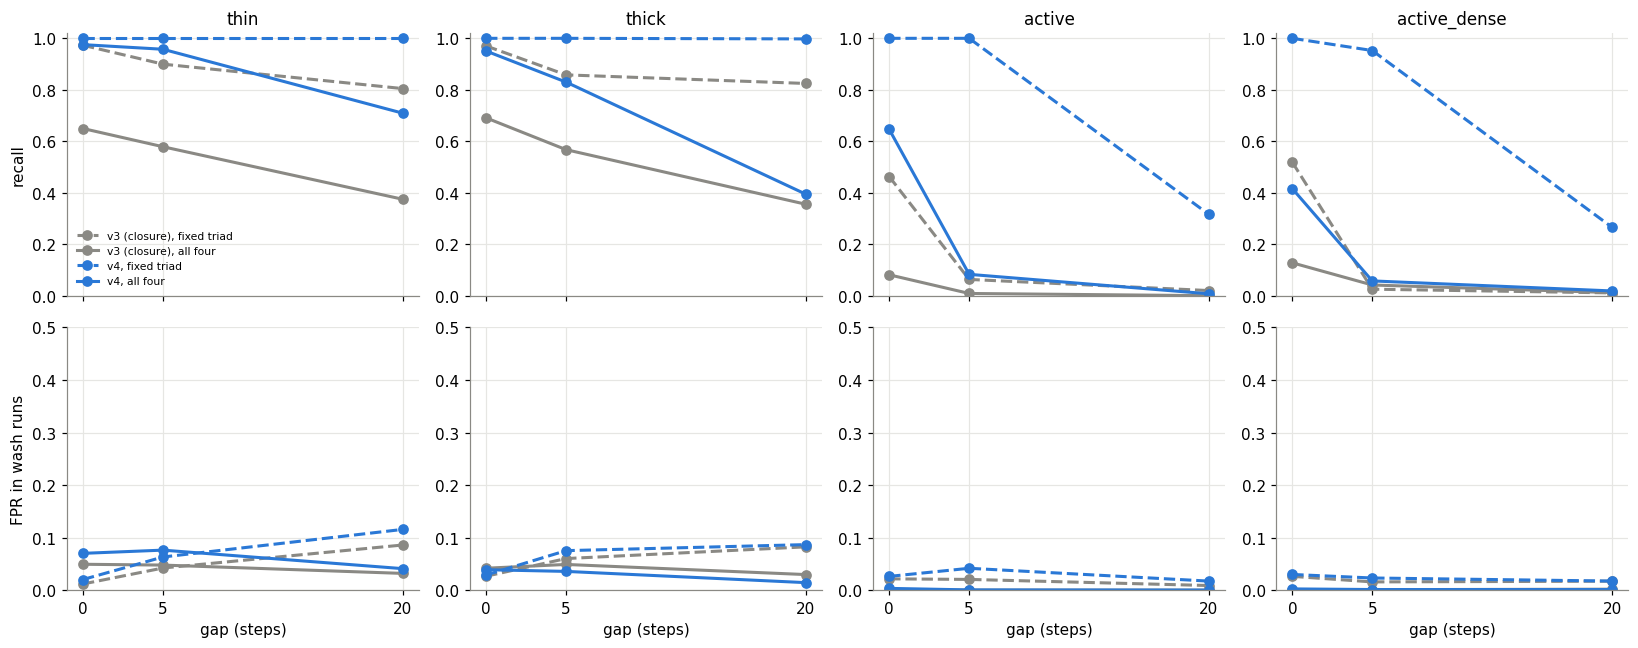

In [7]:
ev = R["evasive"]
w = ev[ev["f_scenario"] == "wash"].copy()
w["adv"] = np.select(
    [(w.f_pool == 3) & (w.f_q_hi == 1) & (w.f_residual_prob == 0) & (w.f_camouflage_total == 0),
     (w.f_pool == 96) & (w.f_q_hi == 4) & (w.f_residual_prob > 0) & (w.f_camouflage_total > 0)],
    ["fixed triad", "all four"], "other")
hd = pooled(w[w.adv != "other"], ["background", "adv", "f_gap", "method"]).reset_index()
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
STY = {("closure", "fixed triad"): ("#8a8984", "--"), ("closure", "all four"): ("#8a8984", "-"),
       ("v4", "fixed triad"): ("#2a78d6", "--"), ("v4", "all four"): ("#2a78d6", "-")}
for j, b in enumerate(BG4):
    for i, met in enumerate(["recall", "fpr"]):
        ax = axes[i][j]
        for (m, a), (c, ls) in STY.items():
            s = hd[(hd.background == b) & (hd.method == m) & (hd.adv == a)].sort_values("f_gap")
            ax.plot(s.f_gap, s[met], ls, color=c, marker="o", label=f"{'v3 (closure)' if m == 'closure' else 'v4'}, {a}")
        ax.set_xticks([0, 5, 20])
        ax.set_ylim(0, 1.02 if met == "recall" else 0.5)
        if i == 0:
            ax.set_title(b)
        if j == 0:
            ax.set_ylabel("recall" if met == "recall" else "FPR in wash runs")
        if i == 1:
            ax.set_xlabel("gap (steps)")
axes[0][0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
display(hd[hd.method.isin(["closure", "v4"])].pivot_table(
    index=["background", "f_gap"], columns=["adv", "method"], values=["recall", "fpr"])
    .reindex(BG4, level=0).round(2))

## 6. All methods, pooled over every wash cell of the `evasive` sweep

Pooled over the 288 wash cells × 200 seeds per background. The table shows recall and
precision at the calibrated threshold, the FPR in wash runs, and the mean AP. Fusion picks up
whichever channel the adversary fails to hide.

In [8]:
pm = pooled(w, ["background", "method"]).reset_index()
for met in ["recall", "fpr", "precision", "ap"]:
    print(met)
    display(pm.pivot(index="method", columns="background", values=met)[BG4]
            .reindex(MAIN + ["roundtrip_50", "roundtrip_200", "repeat_20", "repeat_200"]).round(3))

recall


background,thin,thick,active,active_dense
method,,,,
closure,0.842,0.827,0.186,0.222
roundtrip_100,0.800,0.730,0.579,0.547
repeat_50,0.489,0.302,0.185,0.068
closure+roundtrip,0.961,0.913,0.647,0.620
closure+repeat,0.906,0.898,0.415,0.333
v4,0.972,0.926,0.695,0.647
roundtrip_50,0.453,0.483,0.440,0.403
roundtrip_200,0.952,0.868,0.523,0.485
repeat_20,0.208,0.071,0.046,0.013


fpr


background,thin,thick,active,active_dense
method,,,,
closure,0.164,0.092,0.014,0.016
roundtrip_100,0.108,0.043,0.024,0.014
repeat_50,0.032,0.002,0.000,0.000
closure+roundtrip,0.204,0.087,0.026,0.018
closure+repeat,0.156,0.094,0.015,0.016
v4,0.206,0.085,0.026,0.018
roundtrip_50,0.041,0.018,0.003,0.001
roundtrip_200,0.173,0.053,0.019,0.013
repeat_20,0.007,0.000,0.000,0.000


precision


background,thin,thick,active,active_dense
method,,,,
closure,0.924,0.863,0.586,0.366
roundtrip_100,0.946,0.922,0.723,0.618
repeat_50,0.973,0.991,0.999,1.000
closure+roundtrip,0.918,0.880,0.730,0.590
closure+repeat,0.932,0.870,0.752,0.462
v4,0.918,0.883,0.744,0.600
roundtrip_50,0.963,0.949,0.932,0.931
roundtrip_200,0.929,0.919,0.752,0.597
repeat_20,0.985,0.999,0.999,1.000


ap


background,thin,thick,active,active_dense
method,,,,
closure,0.906,0.844,0.398,0.285
roundtrip_100,0.934,0.835,0.472,0.388
repeat_50,0.880,0.788,0.508,0.416
closure+roundtrip,0.936,0.889,0.526,0.449
closure+repeat,0.916,0.886,0.543,0.467
v4,0.932,0.904,0.610,0.545
roundtrip_50,0.916,0.765,0.430,0.361
roundtrip_200,0.943,0.895,0.447,0.345
repeat_20,0.799,0.639,0.439,0.359


## 7. One tactic at a time (gap 0, no camouflage)

Each row adds one tactic to the fixed triad. Left: v3 (closure). Middle: v4. Right: v4 minus
v3. Recall at the calibrated threshold, pooled over 200 seeds.

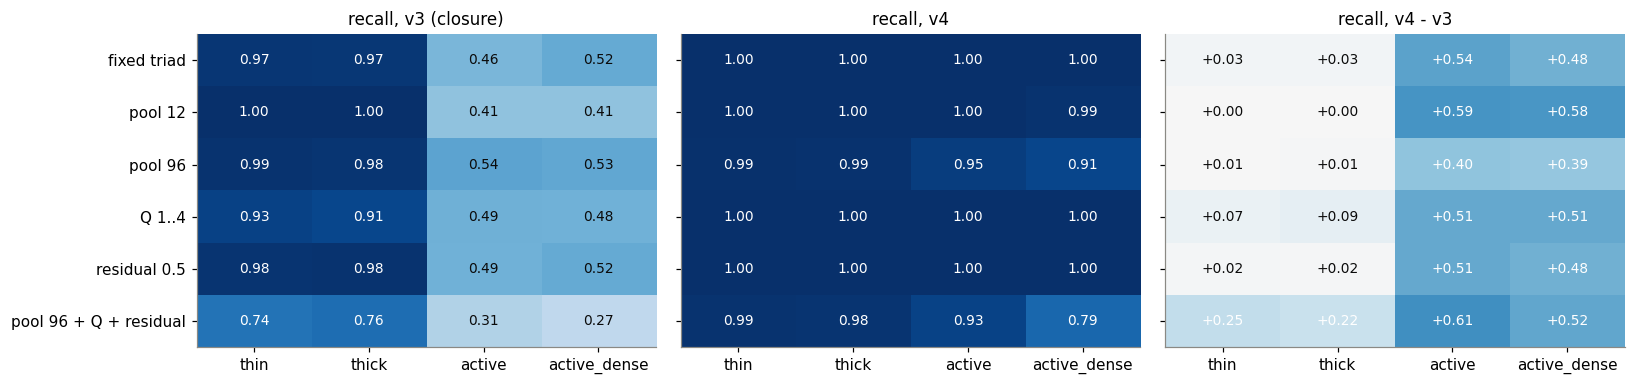

In [9]:
g0 = w[(w.f_gap == 0) & (w.f_camouflage_total == 0)]
TACTICS = [("fixed triad", (3, 1, 0)), ("pool 12", (12, 1, 0)), ("pool 96", (96, 1, 0)),
           ("Q 1..4", (3, 4, 0)), ("residual 0.5", (3, 1, 0.5)), ("pool 96 + Q + residual", (96, 4, 0.5))]
rows = []
for name, (pool_, q, res) in TACTICS:
    s = g0[(g0.f_pool == pool_) & (g0.f_q_hi == q) & (g0.f_residual_prob == res)]
    p = pooled(s, ["background", "method"])["recall"]
    for b in BG4:
        rows.append(dict(tactic=name, background=b, v3=p[(b, "closure")], v4=p[(b, "v4")]))
T = pd.DataFrame(rows)
order = [t for t, _ in TACTICS]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, title, vmin, cmap) in zip(axes, [("v3", "v3 (closure)", 0, "Blues"),
                                                 ("v4", "v4", 0, "Blues"),
                                                 ("diff", "v4 - v3", -1, "RdBu")]):
    piv = (T.assign(diff=T.v4 - T.v3).pivot(index="tactic", columns="background", values=col)
           .reindex(order)[BG4])
    heat(ax, piv, vmin=vmin, vmax=1, cmap=cmap, fmt="{:+.2f}" if col == "diff" else "{:.2f}")
    ax.set_title(f"recall, {title}")
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()

## 8. Score floor: recall vs FPR in wash runs

`evasive` wash cells, v4, pooled. Each point is one floor (0, 0.3, 0.5 = main, 0.7). Without a
floor (0), the repeat channels' near-zero thresholds flag the spillover volume of wash runs. A
higher floor trades recall for less spillover.

fpr                            recall                \
background      thin  thick active active_dense   thin  thick active   
method  floor                                                          
closure 0.0    0.164  0.092  0.014        0.016  0.842  0.827  0.186   
        0.3    0.164  0.092  0.014        0.016  0.842  0.827  0.186   
        0.5    0.164  0.092  0.014        0.016  0.842  0.827  0.186   
        0.7    0.164  0.092  0.014        0.016  0.842  0.827  0.186   
v4      0.0    0.301  0.121  0.044        0.109  0.975  0.928  0.852   
        0.3    0.223  0.084  0.028        0.018  0.977  0.934  0.785   
        0.5    0.206  0.085  0.026        0.018  0.972  0.926  0.695   
        0.7    0.159  0.095  0.022        0.017  0.923  0.915  0.591   

                            
background    active_dense  
method  floor               
closure 0.0          0.222  
        0.3          0.222  
        0.5          0.222  
        0.7          0.222  
v4      0.0          0.841  
        0.3          0.732  
        0.5          0.647  
        0.7          0.553

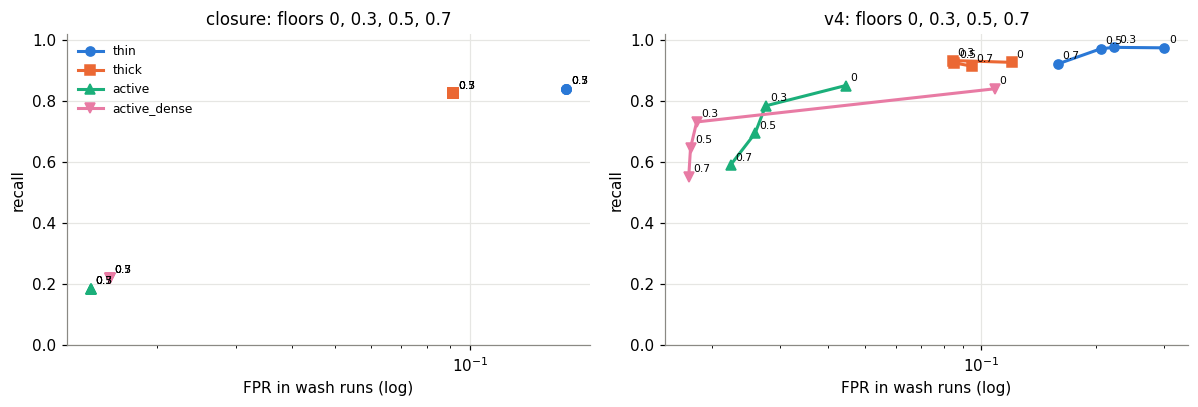

In [10]:
rows = []
for fl in FLOORS:
    tp = "trade_tp" if fl == MAIN_FLOOR else f"trade_tp_{floor_tag(fl)}"
    fp = "trade_fp" if fl == MAIN_FLOOR else f"trade_fp_{floor_tag(fl)}"
    p = pooled(w, ["background", "method"], tp, fp).reset_index().assign(floor=fl)
    rows.append(p)
FL = pd.concat(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, m in zip(axes, ["closure", "v4"]):
    for b in BG4:
        s = FL[(FL.background == b) & (FL.method == m)].sort_values("floor")
        ax.plot(s["fpr"], s["recall"], color=COLOR[b], marker=MARKER[b], label=b)
        for _, r in s.iterrows():
            ax.annotate(f"{r['floor']:g}", (r["fpr"], r["recall"]), fontsize=7,
                        xytext=(3, 3), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("FPR in wash runs (log)")
    ax.set_ylabel("recall")
    ax.set_title(f"{m}: floors " + ", ".join(f"{f:g}" for f in FLOORS))
    ax.set_ylim(0, 1.02)
axes[0].legend(fontsize=8)
fig.tight_layout()
display(FL[FL.method.isin(["closure", "v4"])].pivot_table(index=["method", "floor"], columns="background",
                                                           values=["recall", "fpr"])
        .round(3).reindex(columns=BG4, level=1))

## 9. Single-factor sweeps (gap 0, triads): v3 vs v4

Recall at the calibrated threshold, seed means with 95% intervals. Dashed = v3 (closure),
solid = v4. Left: pool size (`rotation`, cycles of 3). Middle: round size with unit trades
(`size`). Right: residual probability (`residual`, d = 1).

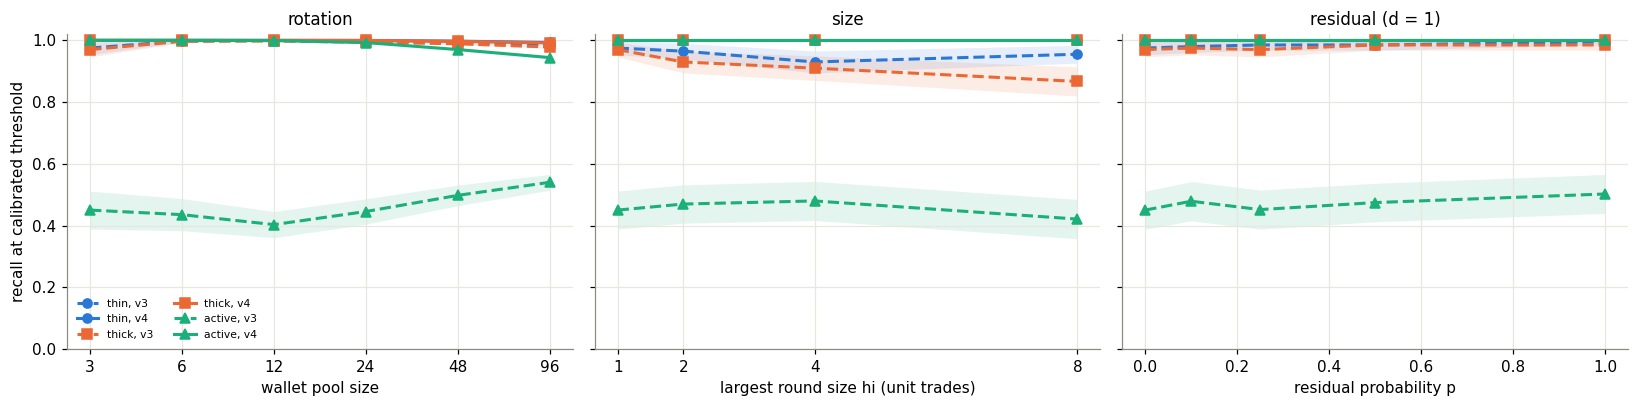

In [11]:
rt, sz, rs = R["rotation"], R["size"], R["residual"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)


def lines(ax, df, x):
    for b in BG3:
        for m, ls in (("closure", "--"), ("v4", "-")):
            d = mean_ci(df[(df.background == b) & (df.method == m)], x, "trade_recall").sort_values(x)
            ax.plot(d[x], d["mean"], ls, color=COLOR[b], marker=MARKER[b],
                    label=f"{b}, {'v3' if m == 'closure' else 'v4'}")
            ax.fill_between(d[x], d["mean"] - d["half"], d["mean"] + d["half"], color=COLOR[b],
                            alpha=0.12, linewidth=0)


lines(axes[0], rt[(rt.f_cycle_len == 3) & (rt.f_gap == 0)], "f_pool")
axes[0].set_xscale("log")
axes[0].minorticks_off()
axes[0].set_xticks([3, 6, 12, 24, 48, 96], ["3", "6", "12", "24", "48", "96"])
axes[0].set_xlabel("wallet pool size")
axes[0].set_ylabel("recall at calibrated threshold")
axes[0].set_title("rotation")
lines(axes[1], sz[(sz.f_gap == 0) & ((sz.f_size_exec == "units") | (sz.f_q_hi == 1))], "f_q_hi")
axes[1].set_xticks([1, 2, 4, 8])
axes[1].set_xlabel("largest round size hi (unit trades)")
axes[1].set_title("size")
lines(axes[2], rs[(rs.f_gap == 0) & ((rs.f_residual_max == 1) | (rs.f_residual_prob == 0))], "f_residual_prob")
axes[2].set_xlabel("residual probability p")
axes[2].set_title("residual (d = 1)")
axes[0].legend(fontsize=7, loc="lower left", ncol=2)
for ax in axes:
    ax.set_ylim(0, 1.02)
fig.tight_layout()

## 10. Ablation: the network step

`evasive` wash cells, pooled. `_noprop` scores a pair by its wallets' initial scores
($x = x^0$), with its own control-calibrated threshold. Propagation is what turns a wallet-level
share into evidence about a pair: a wash wallet's honest counterparties stay low, and its wash
counterparties stay high.

In [12]:
ab = pm[pm.method.isin(["roundtrip_100", "roundtrip_100_noprop", "repeat_50", "repeat_50_noprop"])]
display(ab.pivot_table(index="method", columns="background", values=["recall", "fpr", "ap"])
        .reindex(columns=BG4, level=1).round(3))

ap                               fpr                \
background             thin  thick active active_dense   thin  thick active   
method                                                                        
repeat_50             0.880  0.788  0.508        0.416  0.032  0.002  0.000   
repeat_50_noprop      0.851  0.725  0.446        0.351  0.033  0.006  0.000   
roundtrip_100         0.934  0.835  0.472        0.388  0.108  0.043  0.024   
roundtrip_100_noprop  0.911  0.793  0.421        0.338  0.072  0.017  0.016   

                                  recall                             
background           active_dense   thin  thick active active_dense  
method                                                               
repeat_50                   0.000  0.489  0.302  0.185        0.068  
repeat_50_noprop            0.000  0.496  0.454  0.276        0.156  
roundtrip_100               0.014  0.800  0.730  0.579        0.547  
roundtrip_100_noprop        0.011  0.666  0.535  0.473        0.449

## 11. Summary (200 seeds per cell; pooled control FPR 1%, floor 0.5)

1. **Active markets: the main gain.** Pooled over every wash cell of `evasive`, recall rises from
   0.19 to 0.70 (active) and from 0.22 to 0.65 (active_dense). FPR in wash runs moves from
   1.4% to 2.6% (active) and from 1.6% to 1.8% (active_dense). Precision rises (0.59 → 0.74,
   0.37 → 0.60), and so does AP (0.40 → 0.61, 0.29 → 0.55).
2. **Single tactics no longer work at gap 0.** v4's recall is 0.91–1.00 for each tactic alone,
   against 0.41–0.54 for v3 in the active backgrounds. Against pool 96 + Q 1..4 + residual
   (thin / thick / active / dense) it is 0.99 / 0.98 / 0.93 / 0.79, against v3's
   0.74 / 0.76 / 0.31 / 0.27.
3. **The two new channels cover each other.** The size tactic leaves bursts of same-pair trades,
   because the Q units of a round are executed one at a time on one edge. The repeat channel
   reads those bursts. It is blind to size-1 rounds, which the round-trip channel catches. With
   all four tactics at gap 0 in active, recall is 0.08 for closure, 0.21 for round trips, 0.46
   for repeats and 0.65 fused.
4. **The gap still wins in active markets.** Against all four tactics, recall is
   0.08 / 0.06 (active / dense) at gap 5 and 0.01 / 0.02 at gap 20. A fixed triad at gap 5,
   however, is now caught (0.06 → 1.00 active, 0.03 → 0.95 dense).
5. **The cost is in thin markets.** FPR in wash runs rises from 16.4% to 20.6% (thin) and stays
   about the same in thick (9.2% → 8.5%). The spillover was already large for closure: honest
   volume in thin markets is small, and much of it touches wash or camouflage wallets.
6. **Floor.** Floor 0.3 raises active recall to 0.79 / 0.73 at an FPR of 2.8% / 1.8% in wash runs.
   Floor 0 reaches 0.85 / 0.84, but at 4.4% / 10.9%: that is the near-zero-threshold failure.
7. **Network step.** Without propagation, round-trip recall falls (active 0.58 → 0.47) and AP
   falls for both channels. For repeats, recall without propagation is higher (0.19 → 0.28) at
   lower AP.
8. **Robust to the screening seeds.** The channel windows were screened on seeds 0–29. On seeds
   30–199 alone, every pooled number changes by at most 0.01.